In [1]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from pathlib import Path
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Project directory
PROJECT_DIR = Path.cwd().parent

# Dataset paths
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

TRAIN_CSV = PROCESSED_DIR / "train.csv"
VAL_CSV = PROCESSED_DIR / "validation.csv"
TEST_CSV = PROCESSED_DIR / "test.csv"

# Model directory
MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("TensorFlow Version:", tf.__version__)
print("Project Directory:", PROJECT_DIR)
print("Model Directory:", MODEL_DIR)

print("Training CSV exists:", TRAIN_CSV.exists())
print("Validation CSV exists:", VAL_CSV.exists())
print("Testing CSV exists:", TEST_CSV.exists())

TensorFlow Version: 2.21.0
Project Directory: c:\Banana Sense-AI
Model Directory: c:\Banana Sense-AI\models
Training CSV exists: True
Validation CSV exists: True
Testing CSV exists: True


In [2]:
# Load CSV files
train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_csv(VAL_CSV)
test_df = pd.read_csv(TEST_CSV)

# Display dataset information
print("Training Dataset:", train_df.shape)
print("Validation Dataset:", val_df.shape)
print("Testing Dataset:", test_df.shape)

# Display first five rows
display(train_df.head())

Training Dataset: (573, 3)
Validation Dataset: (123, 3)
Testing Dataset: (123, 3)


,image_path,label,split
0,C:\Banana Sense-AI\data\raw\Banana Ripeness De...,Ripe,train
1,C:\Banana Sense-AI\data\raw\Banana Ripeness De...,Semi-ripe,train
2,C:\Banana Sense-AI\data\raw\Banana Ripeness De...,Overripe,train
3,C:\Banana Sense-AI\data\raw\Banana Ripeness De...,Semi-ripe,train
4,C:\Banana Sense-AI\data\raw\Banana Ripeness De...,Semi-ripe,train


In [3]:
print("Training Class Distribution:")
print(train_df["label"].value_counts())

print("\nValidation Class Distribution:")
print(val_df["label"].value_counts())

print("\nTesting Class Distribution:")
print(test_df["label"].value_counts())

Training Class Distribution:
label
Green        148
Semi-ripe    142
Overripe     142
Ripe         141
Name: count, dtype: int64

Validation Class Distribution:
label
Green        32
Semi-ripe    31
Ripe         30
Overripe     30
Name: count, dtype: int64

Testing Class Distribution:
label
Green        32
Overripe     31
Ripe         30
Semi-ripe    30
Name: count, dtype: int64


In [4]:
IMG_SIZE = 128
BATCH_SIZE = 16
SEED = 42

# Get class names
class_names = sorted(train_df["label"].unique())

# Create label mappings
label_to_id = {
    label: index for index, label in enumerate(class_names)
}

id_to_label = {
    index: label for label, index in label_to_id.items()
}

print("Image Size:", IMG_SIZE)
print("Batch Size:", BATCH_SIZE)
print("Classes:", class_names)
print("Label Mapping:", label_to_id)

Image Size: 128
Batch Size: 16
Classes: ['Green', 'Overripe', 'Ripe', 'Semi-ripe']
Label Mapping: {'Green': 0, 'Overripe': 1, 'Ripe': 2, 'Semi-ripe': 3}


In [5]:
def preprocess_image(image_path, label):
    # Read image
    image = tf.io.read_file(image_path)

    # Decode image
    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    # Resize image
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])

    # Normalize pixel values
    image = image / 255.0

    return image, label

In [6]:
def create_dataset(dataframe, shuffle=False):

    image_paths = dataframe["image_path"].values

    labels = dataframe["label"].map(label_to_id).values

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=SEED
        )

    dataset = dataset.map(
        preprocess_image,
        num_parallel_calls=2
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(1)

    return dataset


# Create datasets
train_ds = create_dataset(train_df, shuffle=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("TensorFlow datasets created successfully!")

TensorFlow datasets created successfully!


In [7]:
images, labels = next(iter(train_ds))

print("Image Batch Shape:", images.shape)
print("Label Batch Shape:", labels.shape)

print("Minimum Pixel Value:", tf.reduce_min(images).numpy())
print("Maximum Pixel Value:", tf.reduce_max(images).numpy())

Image Batch Shape: (16, 128, 128, 3)
Label Batch Shape: (16,)
Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0


In [8]:
model = models.Sequential([

    # Input layer
    layers.Input(shape=(128, 128, 3)),

    # First Convolution Block
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Second Convolution Block
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Third Convolution Block
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Feature extraction
    layers.GlobalAveragePooling2D(),

    # Fully Connected Layer
    layers.Dense(128, activation="relu"),

    # Prevent overfitting
    layers.Dropout(0.4),

    # Output Layer
    layers.Dense(len(class_names), activation="softmax")
])

print("CNN Model Created Successfully!")

CNN Model Created Successfully!


In [9]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,276 (430.77 KB)

 Trainable params: 110,276 (430.77 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [12]:
callbacks = [

    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    ModelCheckpoint(
        filepath=str(MODEL_DIR / "best_banana_cnn.keras"),
        monitor="val_loss",
        save_best_only=True
    )

]

print("Callbacks configured successfully!")

Callbacks configured successfully!


In [13]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks
)

Epoch 1/20


c:\Users\Tejus\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


36/36 ━━━━━━━━━━━━━━━━━━━━ 9s 117ms/step - accuracy: 0.2845 - loss: 1.3896 - val_accuracy: 0.2439 - val_loss: 1.4248
Epoch 2/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 4s 98ms/step - accuracy: 0.3455 - loss: 1.3765 - val_accuracy: 0.7398 - val_loss: 1.3014
Epoch 3/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 4s 97ms/step - accuracy: 0.5550 - loss: 1.1162 - val_accuracy: 0.7398 - val_loss: 0.8430
Epoch 4/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 4s 104ms/step - accuracy: 0.7818 - loss: 0.6337 - val_accuracy: 0.7724 - val_loss: 0.4644
Epoch 5/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 4s 101ms/step - accuracy: 0.7696 - loss: 0.5963 - val_accuracy: 0.9187 - val_loss: 0.4042
Epoch 6/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 4s 103ms/step - accuracy: 0.8621 - loss: 0.4010 - val_accuracy: 0.9431 - val_loss: 0.1750
Epoch 7/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 4s 107ms/step - accuracy: 0.8586 - loss: 0.3455 - val_accuracy: 0.9024 - val_loss: 0.2233
Epoch 8/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 4s 98ms/step - accuracy: 0.8866 - loss: 0.3200 - val_accuracy: 0.9106 - val_los

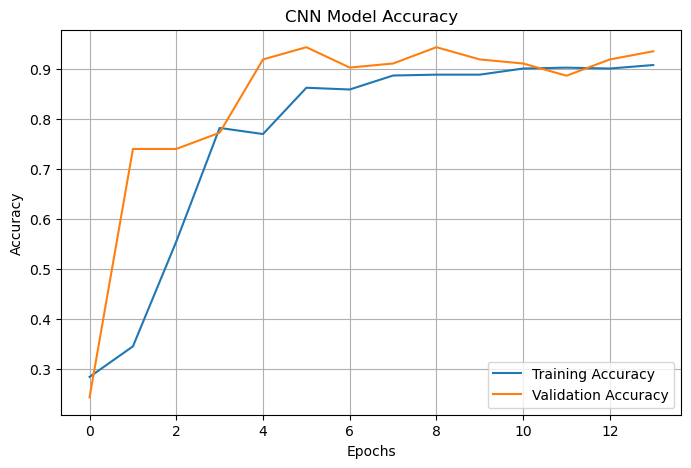

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("CNN Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

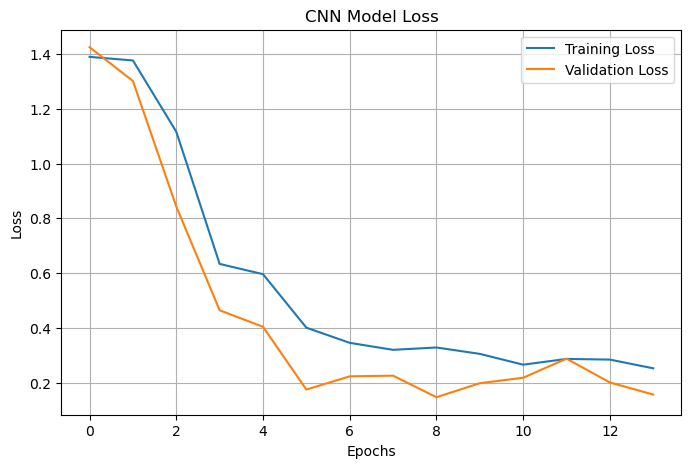

In [15]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("CNN Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

In [16]:
# Evaluate model on unseen test data
test_loss, test_accuracy = model.evaluate(test_ds)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.8862 - loss: 0.2465
Test Accuracy: 88.62%
Test Loss: 0.2465


In [17]:
# Generate predictions
y_pred_probs = model.predict(test_ds)

# Convert probabilities into predicted class IDs
y_pred = np.argmax(y_pred_probs, axis=1)

# Get actual labels
y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

print("Actual Labels:", y_true[:10])
print("Predicted Labels:", y_pred[:10])

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step
Actual Labels: [2 2 2 1 3 3 0 1 2 0]
Predicted Labels: [2 2 2 1 3 0 0 1 2 0]


In [18]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(len(class_names))),
        target_names=class_names,
        zero_division=0
    )
)

              precision    recall  f1-score   support

       Green       0.94      0.97      0.95        32
    Overripe       1.00      0.81      0.89        31
        Ripe       0.84      0.87      0.85        30
   Semi-ripe       0.79      0.90      0.84        30

    accuracy                           0.89       123
   macro avg       0.89      0.89      0.89       123
weighted avg       0.89      0.89      0.89       123



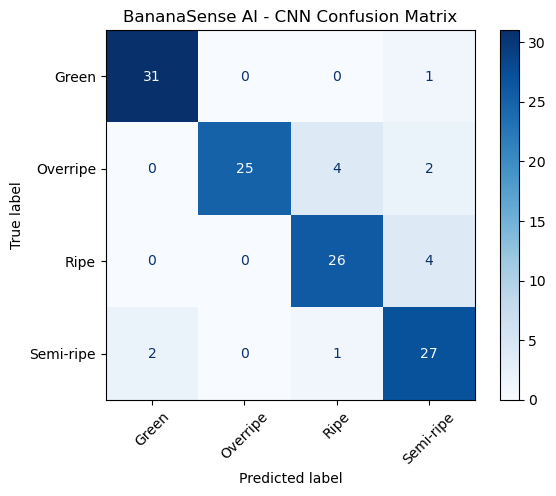

In [19]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    display_labels=class_names,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("BananaSense AI - CNN Confusion Matrix")
plt.show()

In [20]:
BEST_MODEL_PATH = MODEL_DIR / "best_banana_cnn.keras"

best_model = tf.keras.models.load_model(BEST_MODEL_PATH)

print("Best CNN model loaded successfully!")

Best CNN model loaded successfully!


In [21]:
test_loss, test_accuracy = best_model.evaluate(test_ds)

print(f"Final Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Final Test Loss: {test_loss:.4f}")

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.8862 - loss: 0.2465
Final Test Accuracy: 88.62%
Final Test Loss: 0.2465


In [22]:
FINAL_MODEL_PATH = MODEL_DIR / "banana_sense_ai_final.keras"

best_model.save(FINAL_MODEL_PATH)

print("Final model exported successfully!")
print("Saved at:", FINAL_MODEL_PATH)

Final model exported successfully!
Saved at: c:\Banana Sense-AI\models\banana_sense_ai_final.keras


In [23]:
import json

CLASS_MAPPING_PATH = MODEL_DIR / "class_mapping.json"

with open(CLASS_MAPPING_PATH, "w") as f:
    json.dump(id_to_label, f, indent=4)

print("Class mapping saved successfully!")

Class mapping saved successfully!
